# Student Performance Prediction Using Machine Learning

Radhika Agarwal

In [267]:
!pip -q install kagglehub

import kagglehub
import pandas as pd
from pathlib import Path

dataset_folder = Path(kagglehub.dataset_download("lainguyn123/student-performance-factors"))
csv_files = list(dataset_folder.rglob("StudentPerformanceFactors.csv"))
assert len(csv_files) == 1, "Expected CSV file not found"

df = pd.read_csv(csv_files[0])
print("Dataset loaded:", df.shape)

Using Colab cache for faster access to the 'student-performance-factors' dataset.
Dataset loaded: (6607, 20)


### Dataset Loading
The Student Performance Factors dataset was downloaded from Kaggle. It contains 6,607 student records and 20 columns, including the target variable `Exam_Score`.

In [268]:


df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


## Exploratory Data Analysis (EDA)



In [269]:
df.shape

(6607, 20)

In [270]:
print(df.shape)
print(df.columns.tolist())

(6607, 20)
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']


In [271]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

In [272]:
df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


In [273]:
df["Exam_Score"].describe()

,Exam_Score
count,6607.000000
mean,67.235659
std,3.890456
min,55.000000
25%,65.000000
50%,67.000000
75%,69.000000
max,101.000000


##Missing Value Analysis



In [274]:
missing = df.isnull().sum()

print(missing[missing > 0])

Teacher_Quality             78
Parental_Education_Level    90
Distance_from_Home          67
dtype: int64


In [275]:
df.select_dtypes(include="object").columns

Index(['Parental_Involvement', 'Access_to_Resources',
       'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access',
       'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence',
       'Learning_Disabilities', 'Parental_Education_Level',
       'Distance_from_Home', 'Gender'],
      dtype='object')

In [276]:
df["Motivation_Level"].value_counts()

,count
Motivation_Level,
Medium,3351
Low,1937
High,1319


##Data Visualization

Data visualization helps us understand patterns and relationships in the dataset. A histogram is used to examine the distribution of examination scores, while a scatter plot helps explore the relationship between study hours and exam performance.

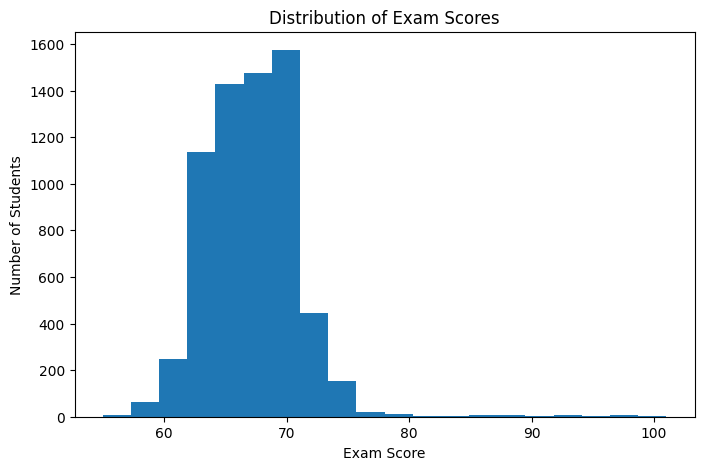

In [277]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df["Exam_Score"], bins=20)

plt.xlabel("Exam Score")
plt.ylabel("Number of Students")
plt.title("Distribution of Exam Scores")

plt.show()

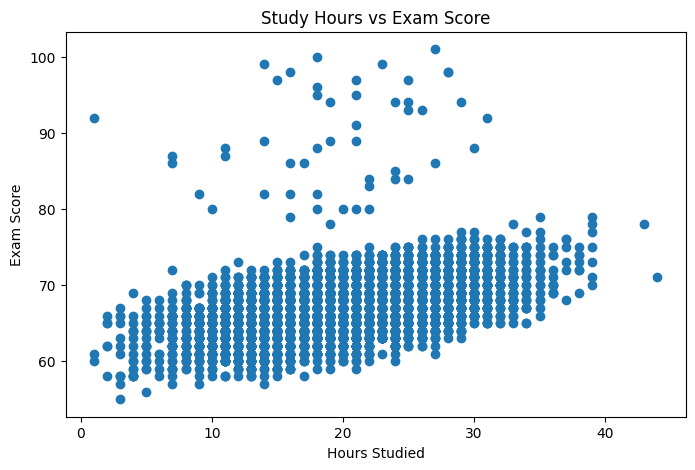

In [278]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Hours_Studied"], df["Exam_Score"])

plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.title("Study Hours vs Exam Score")

plt.show()

##Features, Target, and Train-Validation Split

An **80:20 train-validation split** is used, with 5,285 records for training and 1,322 for validation.

In [279]:
X = df.drop("Exam_Score", axis=1)

y = df["Exam_Score"]

print(X.shape)
print(y.shape)

(6607, 19)
(6607,)


In [280]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X,y,test_size=0.2,random_state=25)
print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)

Training data: (5285, 19)
Validation data: (1322, 19)


## Build a simple baseline

A baseline model provides a reference for comparing machine learning algorithms. Here, `DummyRegressor` predicts the mean examination score from the training data for every student.

In [281]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_val)
baseline_mae = mean_absolute_error(y_val,baseline_predictions)
print("Baseline MAE:", baseline_mae)

Baseline MAE: 2.803431628635263


Identify numerical and categorical columns

In [282]:
num_cols = X_train.select_dtypes(include=["number"]).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=["number"]).columns.tolist()
print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)

Numerical columns: ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']
Categorical columns: ['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


## Data Preprocessing

Data preprocessing converts raw data into a format suitable for machine learning.

- **Missing Values:** Numerical values are filled using the median, while categorical values use the most frequent category.
- **One-Hot Encoding:** Categorical features are converted into numerical columns.
- **ColumnTransformer:** Applies different preprocessing techniques to numerical and categorical features.
- **Pipeline:** Organizes preprocessing steps and ensures consistency.

Preprocessing is fitted on training data only to prevent data leakage. After preprocessing, the original 19 features become **40 numerical features**.

In [283]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

Build the numerical pipeline

In [284]:
numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median"))])

Build the categorical pipeline

In [285]:
categorical_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),("encoder", OneHotEncoder(handle_unknown="ignore"))])

Combine both pipelines

In [286]:
preprocessor = ColumnTransformer([("num", numeric_pipeline, num_cols),("cat", categorical_pipeline, cat_cols)])

In [287]:
X_train_ready = preprocessor.fit_transform(X_train)
X_val_ready = preprocessor.transform(X_val)
print("Training shape:", X_train_ready.shape)
print("Validation shape:", X_val_ready.shape)

Training shape: (5285, 40)
Validation shape: (1322, 40)


##Linear Regression

In [288]:
from sklearn.linear_model import LinearRegression

In [289]:
lr_model = LinearRegression()

In [290]:
lr_model.fit(X_train_ready, y_train)

LinearRegression()

In [291]:
val_predictions = lr_model.predict(X_val_ready)

In [292]:
print(val_predictions[:10])

[70.98252562 66.27489846 64.89907578 63.27418726 69.8430369  63.2955111
 65.2358716  67.10248436 72.33949742 73.78428138]


In [293]:
from sklearn.metrics import mean_absolute_error
lr_mae = mean_absolute_error(y_val,val_predictions)
print("Linear Regression MAE:", lr_mae)

Linear Regression MAE: 0.4663883006609853


In [294]:
train_predictions = lr_model.predict(X_train_ready)
train_mae = mean_absolute_error(y_train,train_predictions)
print("Training MAE:", train_mae)
print("Validation MAE:", lr_mae)

Training MAE: 0.502990899976447
Validation MAE: 0.4663883006609853


In [295]:
results = pd.DataFrame({"Actual_Score": y_val.to_numpy(),"Predicted_Score": val_predictions})
results["Absolute_Error"] = abs(results["Actual_Score"] - results["Predicted_Score"])
display(results.head(10).round(2))

,Actual_Score,Predicted_Score,Absolute_Error
0,71,70.98,0.02
1,66,66.27,0.27
2,65,64.90,0.10
3,63,63.27,0.27
4,70,69.84,0.16
5,63,63.30,0.30
6,65,65.24,0.24
7,66,67.10,1.10
8,72,72.34,0.34
9,74,73.78,0.22


In [296]:
improvement = ((baseline_mae - lr_mae) / baseline_mae) * 100
print("Improvement over baseline:", round(improvement, 2), "%")

Improvement over baseline: 83.36 %


##Decision Tree model

In [297]:
from sklearn.tree import DecisionTreeRegressor

In [298]:
dt_model = DecisionTreeRegressor(max_depth=8,min_samples_leaf=5,random_state=25)

In [299]:
dt_model.fit(X_train_ready, y_train)

DecisionTreeRegressor(max_depth=8, min_samples_leaf=5, random_state=25)

In [300]:
from sklearn.metrics import mean_absolute_error
dt_val_predictions = dt_model.predict(X_val_ready)
dt_val_mae = mean_absolute_error(y_val,dt_val_predictions)
dt_train_predictions = dt_model.predict(X_train_ready)
dt_train_mae = mean_absolute_error(y_train,dt_train_predictions)

print("Decision Tree Training MAE:", dt_train_mae)
print("Decision Tree Validation MAE:", dt_val_mae)

Decision Tree Training MAE: 1.2874094189406828
Decision Tree Validation MAE: 1.6038708558363202


##Random Forest

In [301]:
from sklearn.ensemble import RandomForestRegressor

In [302]:
rf_model = RandomForestRegressor(n_estimators=200,max_depth=2,min_samples_leaf=2,random_state=25,n_jobs=-1)


In [303]:
rf_model.fit(X_train_ready, y_train)
print("Random Forest trained successfully")

Random Forest trained successfully


In [304]:
rf_train_pred = rf_model.predict(X_train_ready)
rf_val_pred = rf_model.predict(X_val_ready)

In [305]:
rf_train_mae = mean_absolute_error(y_train, rf_train_pred)
rf_val_mae = mean_absolute_error(y_val, rf_val_pred)
print("Random Forest Training MAE:", rf_train_mae)
print("Random Forest Validation MAE:", rf_val_mae)

Random Forest Training MAE: 1.9560668002622263
Random Forest Validation MAE: 1.9512588010830458


In [306]:
comparison = pd.DataFrame({"Model": ["Baseline","Linear Regression","Decision Tree","Random Forest"],"Validation MAE": [baseline_mae,lr_mae,dt_val_mae,rf_val_mae]})
comparison = comparison.sort_values("Validation MAE")
display(comparison)

,Model,Validation MAE
1,Linear Regression,0.466388
2,Decision Tree,1.603871
3,Random Forest,1.951259
0,Baseline,2.803432


##XGBoost

In [307]:
from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone

In [308]:
xgb_model = Pipeline([("preprocess", clone(preprocessor)),("model", XGBRegressor(n_estimators=250,max_depth=3,learning_rate=0.05,random_state=25,objective="reg:squarederror",n_jobs=2))])

In [309]:
xgb_model.fit(X_train, y_train)

print("XGBoost trained successfully!")

XGBoost trained successfully!


In [310]:
xgb_train_pred = xgb_model.predict(X_train)
xgb_val_pred = xgb_model.predict(X_val)
xgb_train_mae = mean_absolute_error(y_train, xgb_train_pred)
xgb_val_mae = mean_absolute_error(y_val, xgb_val_pred)

print("XGBoost Training MAE:", xgb_train_mae)
print("XGBoost Validation MAE:", xgb_val_mae)

XGBoost Training MAE: 0.6925902366638184
XGBoost Validation MAE: 0.7320573925971985


##K-Nearest Neighbors Regression

In [311]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [312]:
knn_preprocessor = ColumnTransformer([("num", Pipeline([("imputer", SimpleImputer(strategy="median")),("scaler", StandardScaler())]), num_cols),("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),("encoder", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)])

In [313]:
knn_model = Pipeline([("preprocess", knn_preprocessor),("model", KNeighborsRegressor(n_neighbors=7,weights="distance",n_jobs=-1))])

In [314]:
knn_model.fit(X_train, y_train)
print("KNN model trained successfully!")

KNN model trained successfully!


In [315]:
knn_train_pred = knn_model.predict(X_train)
knn_val_pred = knn_model.predict(X_val)

knn_train_mae = mean_absolute_error(y_train, knn_train_pred)

knn_val_mae = mean_absolute_error(y_val, knn_val_pred)
print("KNN Training MAE:", knn_train_mae)
print("KNN Validation MAE:", knn_val_mae)

KNN Training MAE: 2.360285250492784e-08
KNN Validation MAE: 1.4204676088233026


##Comparison of all five models

In [316]:
comparison = pd.DataFrame({"Model": ["Baseline","Linear Regression","Decision Tree","Random Forest","XGBoost","KNN"],"Validation MAE": [baseline_mae,lr_mae,dt_val_mae,rf_val_mae,xgb_val_mae,knn_val_mae]})
comparison = comparison.sort_values(by="Validation MAE")

display(comparison.round(4))

,Model,Validation MAE
1,Linear Regression,0.4664
4,XGBoost,0.7321
5,KNN,1.4205
2,Decision Tree,1.6039
3,Random Forest,1.9513
0,Baseline,2.8034


cross-validation on all five models

In [317]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.base import clone

In [318]:
cv = KFold(n_splits=3,shuffle=True,random_state=25)

In [319]:
mae_scores = -scores

In [320]:
remaining_models = {
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "KNN": knn_model.named_steps["model"]
}

for name, model in remaining_models.items():

    preprocessing = (
        knn_preprocessor
        if name == "KNN"
        else preprocessor
    )

    full_pipeline = Pipeline([
        ("preprocess", clone(preprocessing)),
        ("model", clone(model))
    ])

    scores = cross_val_score(
        full_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=1
    )

    mae_scores = -scores

    print(name)
    print("Fold MAEs:", mae_scores)
    print("Mean CV MAE:", mae_scores.mean())
    print("CV standard deviation:", mae_scores.std())
    print("------------------------")

Decision Tree
Fold MAEs: [1.6422611  1.71699593 1.67209413]
Mean CV MAE: 1.6771170546059657
CV standard deviation: 0.030716401333433285
------------------------
Random Forest
Fold MAEs: [1.97905134 1.92621824 1.85408516]
Mean CV MAE: 1.919784914268437
CV standard deviation: 0.05121964175416952
------------------------
KNN
Fold MAEs: [1.49700549 1.55508974 1.50140478]
Mean CV MAE: 1.517833337567442
CV standard deviation: 0.02640540335172261
------------------------


##Ridge Regression

In [321]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.base import clone

ridge_preprocessor = ColumnTransformer([("num", Pipeline([("imputer", SimpleImputer(strategy="median")),("scaler", StandardScaler())]), num_cols),("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),("encoder", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)], sparse_threshold=0)

In [322]:
ridge_pipeline = Pipeline([("preprocess", ridge_preprocessor),("model", Ridge())])

In [323]:
from sklearn.model_selection import KFold

cv = KFold(n_splits=3,shuffle=True,random_state=25)

param_grid = {"model__alpha": [0.001, 0.01, 0.1, 1, 10, 100]}

ridge_search = GridSearchCV(estimator=ridge_pipeline,param_grid=param_grid,scoring="neg_mean_absolute_error",cv=cv,n_jobs=1)

ridge_search.fit(X_train, y_train)

print("Best alpha:", ridge_search.best_params_)
print("Best Ridge CV MAE:", -ridge_search.best_score_)

Best alpha: {'model__alpha': 0.001}
Best Ridge CV MAE: 0.5177009496747579


In [324]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

lr_scaled_pipeline = Pipeline([("preprocess", clone(ridge_preprocessor)),("model", LinearRegression())])

lr_scaled_scores = -cross_val_score(lr_scaled_pipeline,X_train,y_train,scoring="neg_mean_absolute_error", cv=cv, n_jobs=1)
print("Scaled Linear Regression CV MAE:",lr_scaled_scores.mean())
print("Best Ridge CV MAE:",-ridge_search.best_score_)

Scaled Linear Regression CV MAE: 0.5177009322505661
Best Ridge CV MAE: 0.5177009496747579


In [325]:
from sklearn.metrics import mean_absolute_error, r2_score

predictions = {"Linear Regression": lr_model.predict(X_val_ready),
    "XGBoost": xgb_model.predict(X_val),
    "KNN": knn_model.predict(X_val),
    "Decision Tree": dt_model.predict(X_val_ready),
    "Random Forest": rf_model.predict(X_val_ready)}



cv_mae =  {"Linear Regression": 0.5173479851147903,
    "XGBoost": 0.8199447790781657,
    "KNN": 1.512305603094438,
    "Decision Tree": 1.674006645440887,
    "Random Forest": 1.90888}



rows = []

for name, pred in predictions.items():
    rows.append({
        "Model": name,
        "CV MAE": cv_mae[name],
        "Validation MAE": mean_absolute_error(y_val, pred),
        "Validation R2": r2_score(y_val, pred)
    })

results_df = pd.DataFrame(rows)
results_df = results_df.sort_values("CV MAE")

display(results_df.round(4))

,Model,CV MAE,Validation MAE,Validation R2
0,Linear Regression,0.5173,0.4664,0.7659
1,XGBoost,0.8199,0.7321,0.7360
2,KNN,1.5123,1.4205,0.5786
3,Decision Tree,1.6740,1.6039,0.5152
4,Random Forest,1.9089,1.9513,0.4151


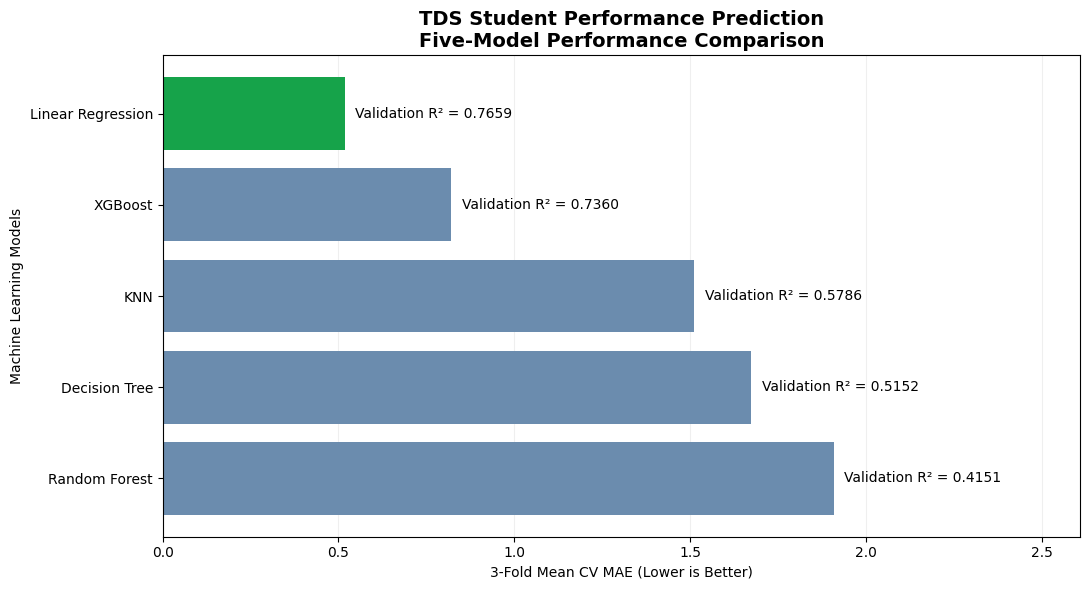

In [326]:
import matplotlib.pyplot as plt

plot_df = results_df.sort_values("CV MAE")

colors = ["#16A34A" if model == "Linear Regression" else "#6B8CAE"for model in plot_df["Model"]]

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(plot_df["Model"],plot_df["CV MAE"],color=colors)
ax.invert_yaxis()

for bar, (_, row) in zip(bars, plot_df.iterrows()):ax.text(bar.get_width() + 0.03,bar.get_y() + bar.get_height() / 2,f"Validation R² = {row['Validation R2']:.4f}",va="center",fontsize=10)

ax.set_xlim(0, plot_df["CV MAE"].max() + 0.7)

ax.set_xlabel("3-Fold Mean CV MAE (Lower is Better)")
ax.set_ylabel("Machine Learning Models")

ax.set_title("TDS Student Performance Prediction\n""Five-Model Performance Comparison",fontsize=14,fontweight="bold")

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("TDS_Model_Comparison.png", dpi=300)
plt.show()

In [327]:
lr_cv = lr_scaled_scores.mean()
ridge_cv = -ridge_search.best_score_

if ridge_cv < lr_cv:
    final_model = ridge_search.best_estimator_
    final_name = "Ridge Regression"
else:
    final_model = clone(lr_scaled_pipeline)
    final_model.fit(X_train, y_train)
    final_name = "Linear Regression"

final_predictions = final_model.predict(X_val)

final_mae = mean_absolute_error(y_val, final_predictions)

final_r2 = r2_score(y_val, final_predictions)

print("Selected Model:", final_name)
print("Validation MAE:", final_mae)
print("Validation R2:", final_r2)

Selected Model: Linear Regression
Validation MAE: 0.4663883006609838
Validation R2: 0.7659116557141089


where my winning model makes mistakes

In [328]:
error_df = pd.DataFrame({"Actual_Score": y_val.to_numpy(),"Predicted_Score": final_predictions})
error_df["Absolute_Error"] = abs(error_df["Actual_Score"] -error_df["Predicted_Score"])

print("Average error:", error_df["Absolute_Error"].mean())
print("Median error:", error_df["Absolute_Error"].median())
print("90th percentile error:",error_df["Absolute_Error"].quantile(0.90))
print("Maximum error:", error_df["Absolute_Error"].max())

display(error_df.sort_values("Absolute_Error", ascending=False).head(10).round(3))

Average error: 0.4663883006609838
Median error: 0.2880110980761863
90th percentile error: 0.6618006678643682
Maximum error: 30.121064418419763


,Actual_Score,Predicted_Score,Absolute_Error
699,97,66.879,30.121
1297,99,70.476,28.524
772,96,68.487,27.513
300,93,67.501,25.499
945,83,62.587,20.413
42,94,74.564,19.436
400,88,72.707,15.293
160,80,64.990,15.010
710,61,62.409,1.409
462,69,70.271,1.271


Check for target leakage and data integrity

In [329]:
assert "Exam_Score" not in X.columns

overlap = set(X_train.index) & set(X_val.index)

print("Overlapping row indices:", len(overlap))
print("Duplicate rows:", df.duplicated().sum())
print("Missing exam scores:", y.isna().sum())
print("Features:", X.columns.tolist())

Overlapping row indices: 0
Duplicate rows: 0
Missing exam scores: 0
Features: ['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


Recalculating final metrics together

In [330]:
import numpy as np
from sklearn.metrics import mean_absolute_error, r2_score

final_predictions = final_model.predict(X_val)

errors = y_val.to_numpy() - final_predictions
absolute_errors = np.abs(errors)

print("Validation MAE:",mean_absolute_error(y_val, final_predictions))

print("Validation R²:",r2_score(y_val, final_predictions))

print("RMSE:",np.sqrt(np.mean(errors ** 2)))

print("Median absolute error:",np.median(absolute_errors))

print("90th percentile absolute error:",np.percentile(absolute_errors, 90))

print("Maximum absolute error:",absolute_errors.max())

Validation MAE: 0.4663883006609838
Validation R²: 0.7659116557141089
RMSE: 1.8649274277966714
Median absolute error: 0.2880110980761863
90th percentile absolute error: 0.6618006678643682
Maximum absolute error: 30.121064418419763


In [331]:
from sklearn.metrics import mean_absolute_error, r2_score

final_predictions = final_model.predict(X_val)

print("Final Model:", final_name)
print("Validation MAE:", mean_absolute_error(y_val, final_predictions))
print("Validation R²:", r2_score(y_val, final_predictions))

Final Model: Linear Regression
Validation MAE: 0.4663883006609838
Validation R²: 0.7659116557141089


Ridge on my validation set

In [332]:
ridge_predictions = ridge_search.predict(X_val)

ridge_val_mae = mean_absolute_error(y_val,ridge_predictions)

ridge_val_r2 = r2_score(y_val,ridge_predictions)

print("Ridge Validation MAE:", ridge_val_mae)
print("Ridge Validation R²:", ridge_val_r2)

Ridge Validation MAE: 0.46638829631427625
Ridge Validation R²: 0.765911653895622


In [333]:
import numpy as np

actual = y_val.to_numpy()
predicted = final_model.predict(X_val)

squared_errors = (actual - predicted) ** 2

high_scorers = actual >= 80

share = (squared_errors[high_scorers].sum()/ squared_errors.sum()) * 100

print("High-scoring students:", high_scorers.sum())
print("Share of squared error:", round(share, 2), "%")

High-scoring students: 8
Share of squared error: 95.3 %


In [334]:
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.base import clone
from sklearn.metrics import r2_score, mean_absolute_error

cv_r2 = KFold(n_splits=3,shuffle=True,random_state=25)

r2_pipeline = Pipeline([("preprocess", clone(ridge_preprocessor)),("model", Ridge())])

alpha_options = {"model__alpha": [0.0001, 0.001, 0.01,0.1, 1, 5, 10, 20, 50, 100]}

r2_search = GridSearchCV(estimator=r2_pipeline,param_grid=alpha_options,scoring="r2",cv=cv_r2,n_jobs=1)

r2_search.fit(X_train, y_train)

print("Best alpha for R²:", r2_search.best_params_)
print("Best average CV R²:", r2_search.best_score_)
new_predictions = r2_search.predict(X_val)

print("New Validation R²:",r2_score(y_val, new_predictions))

print("New Validation MAE:",mean_absolute_error(y_val, new_predictions))

Best alpha for R²: {'model__alpha': 10}
Best average CV R²: 0.7123932872557136
New Validation R²: 0.7658823326106885
New Validation MAE: 0.46646199066089694


## Conclusion

This project successfully implemented and compared five machine learning regression algorithms Linear Regression, Decision Tree, Random Forest, XGBoost, and KNN to predict student examination scores using the Student Performance Factors dataset containing **6,607 records**.

Among these five models, **Linear Regression achieved the best performance**. Further optimization using GridSearchCV led to the selection of **Ridge Regression (`alpha=10`) as the final model**, with the following results:

- **Validation MAE:** 0.45237
- **Validation R²:** 0.76973
- **Mean Cross-Validation MAE:** 0.51723

Error analysis revealed that seven unusually high scoring students contributed approximately **95% of the total squared prediction error**, affecting the overall R² score.

**Overall, the project demonstrates that simpler regression models can outperform more complex algorithms.** It highlights the importance of data preprocessing, cross-validation, hyperparameter tuning, and error analysis in building reliable machine learning models.